# ENTROPY
### Predicting the hidden cost of sending money to Africa

```
root@entropy:~# infer --target total_cost_pct --corridor *>AFRICA
```

**Mission.** Make financial infrastructure in Africa fairer and cheaper: transparent, low-cost rails for remittances, digital identity and peer-to-peer commerce.

**Problem.** Sub-Saharan Africa is the most expensive region in the world to send money to. A $200 transfer loses about 8% on average, while the UN target (SDG 10.c) is **3%**. Much of that cost is not the visible fee but the **FX margin** hidden inside the exchange rate. That makes the pricing *high-entropy*: the same transfer can cost 1% or 30% depending on the corridor and the service.

**Use case: who uses the prediction, and for what.**

| User | What they do with the predicted cost |
|---|---|
| **Remittance / blockchain fintech teams** (e.g. a stablecoin remittance rail) | Benchmark the all-in price incumbents charge for a given corridor and service profile, i.e. the number their product has to beat. |
| **Central-bank & regulator analysts** | Flag corridors and service types whose expected cost sits far above the 3% SDG target. |

**Target.** `total_cost_pct`: the all-in cost (fee + FX margin) of sending the equivalent of **USD 200**, as a % of the amount sent. It is continuous, so this is a regression problem.

| Dataset card | |
|---|---|
| Source | World Bank, **Remittance Prices Worldwide** (RPW): [datacatalog.worldbank.org/search/dataset/0037898](https://datacatalog.worldbank.org/search/dataset/0037898/remittance-prices-worldwide) |
| Licence | CC BY 4.0 (attribution: *The World Bank, Remittance Prices Worldwide, remittanceprices.worldbank.org*) |
| Slice used | Every price quote sent **into an African country**, Q2 2016 to Q3 2025 |
| Collection | Mystery-shopping of real remittance providers each quarter (not synthetic) |

## 0. Setup

In [1]:
import tempfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50, "display.width", 160, "display.max_colwidth", 120)

# ENTROPY plot theme: terminal-dark surface; series colours validated for contrast and colour-blind separation.
SURFACE, INK, MUTED, GRID = "#0B0F0C", "#D7E0D9", "#8A968D", "#1C241F"
GREEN, BLUE, AMBER, ROSE = "#22B05F", "#3B9BE0", "#C27E00", "#DC4C7C"
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
MONO = next(f for f in ["JetBrains Mono", "Consolas", "DejaVu Sans Mono"] if f in installed_fonts)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.axisbelow": True, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.family": "monospace", "font.monospace": [MONO],
    "figure.dpi": 110,
})
SDG_TARGET = 3.0  # SDG 10.c: remittance cost below 3%

## 1. Load the data

The repo ships the Africa slice as a compressed CSV. If it is missing, the cell rebuilds it from the World Bank's official workbook (48 MB) with a single filter: *destination country is one of the 54 African states*.

In [2]:
DATA_PATH = Path("data/rpw_africa_2016q2_2025q3.csv.gz")
RPW_URL = ("https://datacatalogfiles.worldbank.org/ddh-published/0037898/DR0095523/"
           "rpw_dataset_2011_2025_q3.xlsx")
AFRICA_ISO3 = set(
    "DZA AGO BEN BWA BFA BDI CPV CMR CAF TCD COM COD COG CIV DJI EGY GNQ ERI SWZ ETH GAB GMB GHA GIN "
    "GNB KEN LSO LBR LBY MDG MWI MLI MRT MUS MAR MOZ NAM NER NGA RWA STP SEN SYC SLE SOM ZAF SSD SDN "
    "TZA TGO TUN UGA ZMB ZWE".split()
)

if not DATA_PATH.exists():
    request = urllib.request.Request(RPW_URL, headers={"User-Agent": "Mozilla/5.0 (entropy-notebook)"})
    with tempfile.TemporaryDirectory() as tmp:
        workbook = Path(tmp) / "rpw.xlsx"
        workbook.write_bytes(urllib.request.urlopen(request, timeout=300).read())
        world = pd.read_excel(workbook, sheet_name="Dataset (from Q2 2016)")
    DATA_PATH.parent.mkdir(exist_ok=True)
    world[world["destination_code"].isin(AFRICA_ISO3)].to_csv(DATA_PATH, index=False)

raw = pd.read_csv(DATA_PATH, low_memory=False)
numeric_cols = raw.select_dtypes("number").columns
print(f"{len(raw):,} rows x {raw.shape[1]} columns "
      f"({len(numeric_cols)} numeric, {raw.shape[1] - len(numeric_cols)} categorical/text)")
print(f"{raw['destination_code'].nunique()} African destination countries | "
      f"{raw['source_code'].nunique()} sending countries | {raw['firm'].nunique()} providers | "
      f"{raw['period'].nunique()} quarters ({raw['period'].min()} to {raw['period'].max()})")
raw.head(3)

52,892 rows x 47 columns (15 numeric, 32 categorical/text)
38 African destination countries | 29 sending countries | 247 providers | 37 quarters (2016_2Q to 2025_3Q)


,id,period,source_code,source_name,source_region,source_income,source_lending,source_G8G20,destination_code,destination_name,destination_region,destination_income,destination_lending,destination_G8G20,firm,firm_type,payment instrument,access point,speed actual,cc1 lcu amount,cc1 denomination amount,cc1 lcu code,cc1 lcu fee,cc1 lcu fx rate,cc1 fx margin,cc1 total cost %,cc2 lcu amount,cc2 denomination amount,cc2 lcu code,cc2 lcu fee,cc2 lcu fx rate,cc2 fx margin,cc2 total cost %,inter lcu bank fx,transparent,Standard Note,note2,receiving network coverage,pickup location,pickup method,date,corridor,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46
0,620160001,2016_2Q,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,..,NAM,Namibia,Sub-Saharan Africa,Upper middle income,IBRD,..,MoneyGram,Money Transfer Operator,Cash,Agent,Less than one hour,33000.0,200.0,AOA,2900.0,0.084,7.49,16.28,83000.0,500.0,AOA,5700.0,0.084,7.49,14.36,0.0908,yes,NaN,NaN,High,Agent,Cash,11/May/2016,AGONAM,NaN,NaN,NaN,NaN,NaN
1,620160002,2016_2Q,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,..,NAM,Namibia,Sub-Saharan Africa,Upper middle income,IBRD,..,Real Transfer,Money Transfer Operator,"Bank account transfer,Cash",Agent,Same day,33000.0,200.0,AOA,3300.0,0.087,4.19,14.19,83000.0,500.0,AOA,6300.0,0.087,4.19,11.78,0.0908,yes,NaN,NaN,High,Agent,Cash,11/May/2016,AGONAM,NaN,NaN,NaN,NaN,NaN
2,620160003,2016_2Q,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,..,NAM,Namibia,Sub-Saharan Africa,Upper middle income,IBRD,..,Standard Bank,Bank,Bank account transfer,Bank branch,Next day,33000.0,200.0,AOA,9075.0,1.000,0.00,27.50,83000.0,500.0,AOA,9075.0,1.000,0.00,10.93,1.0000,no,This RSP is not transparent: the exchange rate applied to the transaction was not disclosed. The 0% in the exchange ...,NaN,Low,NaN,Bank account,11/May/2016,AGONAM,NaN,NaN,NaN,NaN,NaN


## 2. Clean the target

`cc1 total cost %` is the target. A *negative* cost would mean the provider paid the sender to transact, and costs above **40%** of the amount sent sit beyond the 99.5th percentile. Both are recording errors (wrong amount or currency keyed in), so those rows are removed rather than allowed to dominate a squared-error loss.

In [3]:
TARGET = "total_cost_pct"
MAX_PLAUSIBLE_COST = 40.0

audit = {"raw quotes": len(raw)}
df = raw.drop_duplicates(subset=raw.columns.drop("id"))
audit["exact duplicate quotes removed"] = len(df)
df = df.assign(**{TARGET: pd.to_numeric(df["cc1 total cost %"], errors="coerce")}).dropna(subset=[TARGET])
audit["missing target removed"] = len(df)
df = df[df[TARGET].between(0, MAX_PLAUSIBLE_COST)]
audit[f"cost outside 0-{MAX_PLAUSIBLE_COST:.0f}% removed"] = len(df)
pd.Series(audit, name="rows remaining").to_frame()

,rows remaining
raw quotes,52892
exact duplicate quotes removed,52886
missing target removed,52885
cost outside 0-40% removed,51994


## 3. Feature engineering

### 3.1 Columns dropped, and why

| Dropped column(s) | Reason |
|---|---|
| `cc1 lcu fee`, `cc1 fx margin`, `cc1 lcu fx rate`, `inter lcu bank fx`, `cc1 lcu amount` | **Target leakage.** The target *is* fee/amount + FX margin, so a model given these would copy the answer rather than learn it. They are also unknown until a quote has already been made, so a user could not supply them (proof in the next cell). |
| every `cc2 …` column | The same quote priced for USD 500: a second version of the target, so also leakage. |
| `cc1 denomination amount` | Constant (always 200), so it carries no information. |
| `cc1 lcu code` | Sending currency is fully determined by the sending country. |
| `source_name/region/income/lending/G8G20`, `destination_…` equivalents, `corridor` | Fully determined by the country codes we keep, so they are redundant and add collinearity. |
| `firm` | 247 brand names: an identifier, not a service characteristic. ENTROPY benchmarks *service profiles*, so it must work for a brand-new provider. |
| `id`, `date`, `Standard Note`, `note2`, `Unnamed: 42-46`, `pickup location` | Row IDs, free-text notes, empty spreadsheet columns, and a field that is mostly blank and duplicated by `pickup method`. |
| `period` | Re-expressed as numeric `year` and `quarter`. |

In [4]:
leaky = df[["cc1 fx margin", "cc2 total cost %"]].apply(pd.to_numeric, errors="coerce")
leaky = leaky.assign(**{"fee as % of amount": pd.to_numeric(df["cc1 lcu fee"], errors="coerce")
                        / pd.to_numeric(df["cc1 lcu amount"], errors="coerce") * 100})
leaky.corrwith(df[TARGET]).round(3).rename("correlation with target").to_frame()

,correlation with target
cc1 fx margin,0.442
cc2 total cost %,0.872
fee as % of amount,0.867


### 3.2 Building the candidate inputs

Several raw fields hold comma-separated *lists* (e.g. `"Bank account transfer,Debit/credit card"`). Each token is mapped to one canonical level. A quote offering several distinct levels becomes `MULTI`. Free-text speed becomes a number of hours, and the `period` string becomes `year` + `quarter`. Rare tokens with no stable meaning (24 quotes paid out via ATM or debit card) are dropped, so the API can reject them instead of guessing.

In [5]:
SPEED_HOURS = {"Less than one hour": 1, "Same day": 12, "Next day": 24, "2 days": 48,
               "3-5 days": 96, "6 days or more": 144}
FIRM_TYPE = {"bank": "BANK", "money transfer operator": "MTO", "mobile operator": "MOBILE_OPERATOR",
             "post office": "POST", "non-bank fi": "NON_BANK_FI"}
PAYMENT = {"cash": "CASH", "bank account transfer": "BANK_ACCOUNT", "debit card": "CARD", "credit card": "CARD",
           "debit/credit card": "CARD", "prepaid card": "CARD", "mobile money": "MOBILE_MONEY"}
ACCESS = {"agent": "AGENT", "internet": "ONLINE", "bank branch": "BRANCH", "call center": "CALL_CENTER",
          "post office branch": "POST_OFFICE", "post office": "POST_OFFICE", "mobile phone": "MOBILE_APP"}
PICKUP = {"cash": "CASH", "bank account": "BANK_ACCOUNT", "own/partner bank account": "BANK_ACCOUNT",
          "bank account (same/partner bank)": "BANK_ACCOUNT", "mobile wallet": "MOBILE_WALLET"}


def canonical(value, vocabulary, sep=","):
    # One canonical level per quote; several distinct levels -> MULTI; any unknown token -> None (row dropped).
    levels = {vocabulary.get(token.strip().lower()) for token in str(value).split(sep)}
    if None in levels:
        return None
    return levels.pop() if len(levels) == 1 else "MULTI"


period = df["period"].str.extract(r"(?P<year>\d{4})_(?P<quarter>\d)Q").astype(int)
data = pd.DataFrame({
    "source_country": df["source_code"],
    "destination_country": df["destination_code"],
    "firm_type": df["firm_type"].map(lambda v: canonical(v, FIRM_TYPE, sep="/")),
    "payment_instrument": df["payment instrument"].map(lambda v: canonical(v, PAYMENT)),
    "access_point": df["access point"].map(lambda v: canonical(v, ACCESS)),
    "pickup_method": df["pickup method"].map(lambda v: canonical(v, PICKUP)),
    "network_coverage": df["receiving network coverage"].str.upper(),
    "transparent": df["transparent"].str.lower(),
    "speed_hours": df["speed actual"].map(SPEED_HOURS),
    "year": period["year"],
    "quarter": period["quarter"],
    TARGET: df[TARGET],
}).dropna().reset_index(drop=True)
data["speed_hours"] = data["speed_hours"].astype(int)

CATEGORICAL = ["source_country", "destination_country", "firm_type", "payment_instrument",
               "access_point", "pickup_method", "network_coverage", "transparent"]
NUMERIC_CANDIDATES = ["speed_hours", "year", "quarter"]
CANDIDATES = CATEGORICAL + NUMERIC_CANDIDATES

print(f"{len(data):,} clean quotes | {len(CANDIDATES)} candidate features "
      f"({len(CATEGORICAL)} categorical + {len(NUMERIC_CANDIDATES)} numeric)")
pd.DataFrame({"levels": data[CATEGORICAL].nunique(),
              "values": [sorted(data[c].unique()) if data[c].nunique() < 10 else "ISO3 codes"
                         for c in CATEGORICAL]})

51,970 clean quotes | 11 candidate features (8 categorical + 3 numeric)


,levels,values
source_country,29,ISO3 codes
destination_country,38,ISO3 codes
firm_type,6,"[BANK, MOBILE_OPERATOR, MTO, MULTI, NON_BANK_FI, POST]"
payment_instrument,5,"[BANK_ACCOUNT, CARD, CASH, MOBILE_MONEY, MULTI]"
access_point,7,"[AGENT, BRANCH, CALL_CENTER, MOBILE_APP, MULTI, ONLINE, POST_OFFICE]"
pickup_method,3,"[BANK_ACCOUNT, CASH, MOBILE_WALLET]"
network_coverage,3,"[HIGH, LOW, MEDIUM]"
transparent,2,"[no, yes]"


### 3.3 Hold out the newest quarter as "new data"

**Q3 2025** is the World Bank's most recent release. It is removed *now*, before any exploration or training, and saved later as the CSV uploaded to the API's `/retrain` endpoint. This simulates the real event "a new quarter of prices is published" with genuine data the model has never seen.

In [6]:
is_newest = (data["year"] == 2025) & (data["quarter"] == 3)
new_quarter = data[is_newest].reset_index(drop=True)
data = data[~is_newest].reset_index(drop=True)
print(f"modelling set: {len(data):,} quotes (2016 Q2 to 2025 Q1) | held-out new quarter: {len(new_quarter):,} quotes")

modelling set: 50,248 quotes (2016 Q2 to 2025 Q1) | held-out new quarter: 1,722 quotes


## 4. Explore

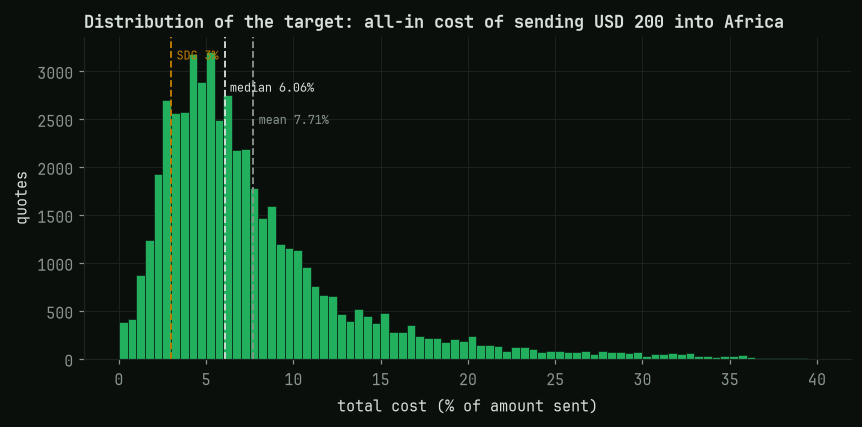

median 6.06% | mean 7.71% | skew 1.96 | 84% of quotes above the SDG target | 95th pct 19.9%


In [7]:
y = data[TARGET]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(y, bins=80, color=GREEN, edgecolor=SURFACE, linewidth=0.4)
for height, (value, label, color) in zip([0.93, 0.83, 0.73], [
        (SDG_TARGET, f"SDG {SDG_TARGET:.0f}%", AMBER),
        (y.median(), f"median {y.median():.2f}%", INK),
        (y.mean(), f"mean {y.mean():.2f}%", MUTED)]):
    ax.axvline(value, color=color, linestyle="--", linewidth=1.2)
    ax.text(value + 0.3, ax.get_ylim()[1] * height, label, color=color, fontsize=8)
ax.set(title="Distribution of the target: all-in cost of sending USD 200 into Africa",
       xlabel="total cost (% of amount sent)", ylabel="quotes")
plt.show()
print(f"median {y.median():.2f}% | mean {y.mean():.2f}% | skew {y.skew():.2f} | "
      f"{(y > SDG_TARGET).mean():.0%} of quotes above the SDG target | 95th pct {y.quantile(.95):.1f}%")

**4.1 Target distribution.** **What it shows:** costs are right-skewed (skew 1.96), with a median of 6.06%, a mean of 7.71% and a long tail out to 40%. **84% of quotes are above the 3% SDG target.**
**Decision:** keep the target in plain percentage points, with no log transform, so both the test MSE and the API's answer are directly interpretable. Squared error punishes misses on the expensive tail hardest, which is why implausible >40% records were removed first, and why models that can isolate expensive segments should do best.

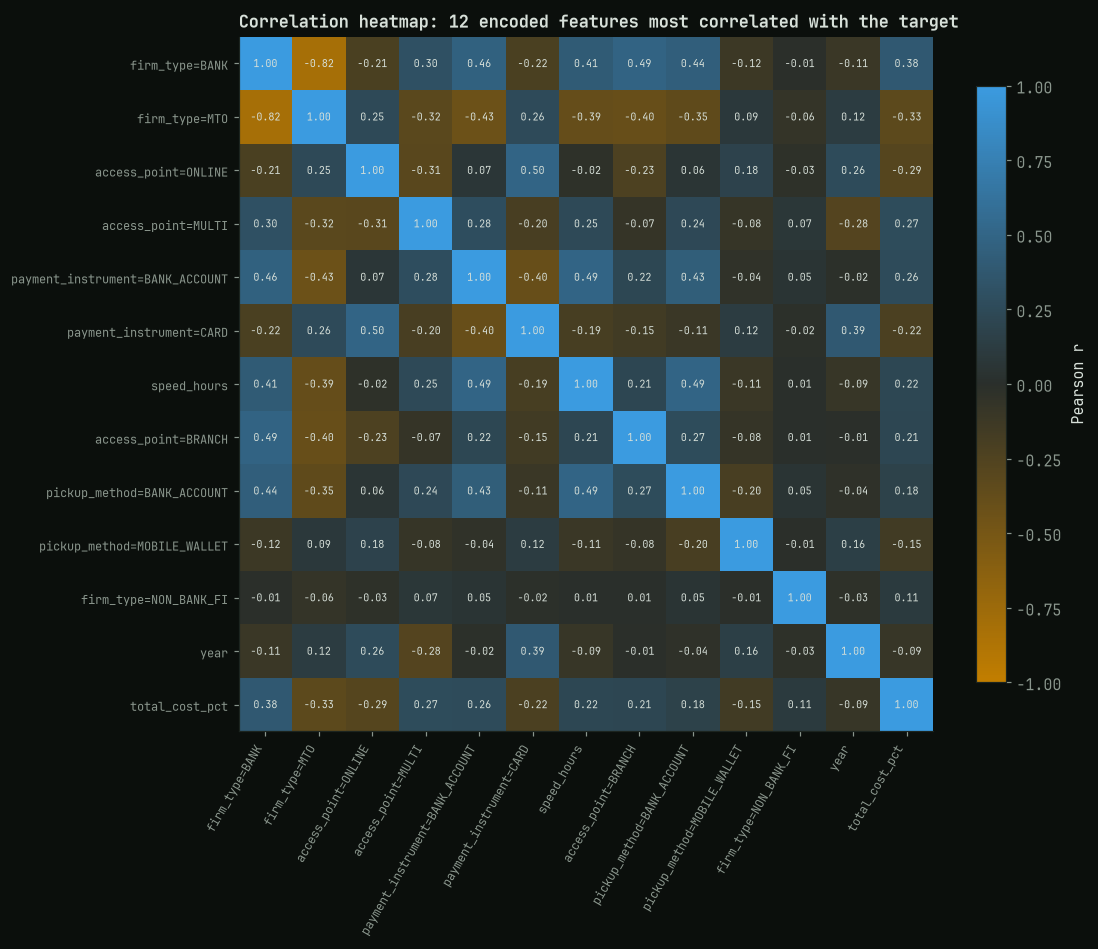

,r with target
firm_type=MTO,-0.334
access_point=ONLINE,-0.288
payment_instrument=CARD,-0.224
pickup_method=MOBILE_WALLET,-0.152
year,-0.092
firm_type=NON_BANK_FI,0.106
pickup_method=BANK_ACCOUNT,0.179
access_point=BRANCH,0.214
speed_hours,0.222
payment_instrument=BANK_ACCOUNT,0.258


In [8]:
encoded = pd.get_dummies(data[CATEGORICAL[2:]], prefix_sep="=", dtype=float).join(data[NUMERIC_CANDIDATES + [TARGET]])
top = encoded.corr()[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(12).index
corr = encoded[list(top) + [TARGET]].corr()

diverging = LinearSegmentedColormap.from_list("entropy_div", [AMBER, "#2A2F2B", BLUE])
fig, ax = plt.subplots(figsize=(10, 8.2))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color=INK)
fig.colorbar(im, ax=ax, fraction=0.035, label="Pearson r")
ax.set_title("Correlation heatmap: 12 encoded features most correlated with the target")
plt.show()
corr[TARGET].drop(TARGET).sort_values().round(3).to_frame("r with target")

**4.2 Correlation heatmap.** **What it shows:** being a **bank** is the strongest single encoded signal (r = +0.38). Money-transfer operators (-0.33), online access (-0.29), card funding (-0.22) and mobile-wallet pickup (-0.15) all pull cost down, and `year` (-0.09) shows prices slowly falling. The inputs are also correlated with *each other* (BANK vs MTO -0.82, card vs online +0.50, speed vs bank-account funding +0.49).
**Decision:** no feature is strongly linear on its own (|r| <= 0.38), so the signal lives in *combinations*. Keep all inputs, regularise the gradient-descent model (`alpha`) against the collinearity, and expect tree models, which learn interactions, to beat the straight-line models.

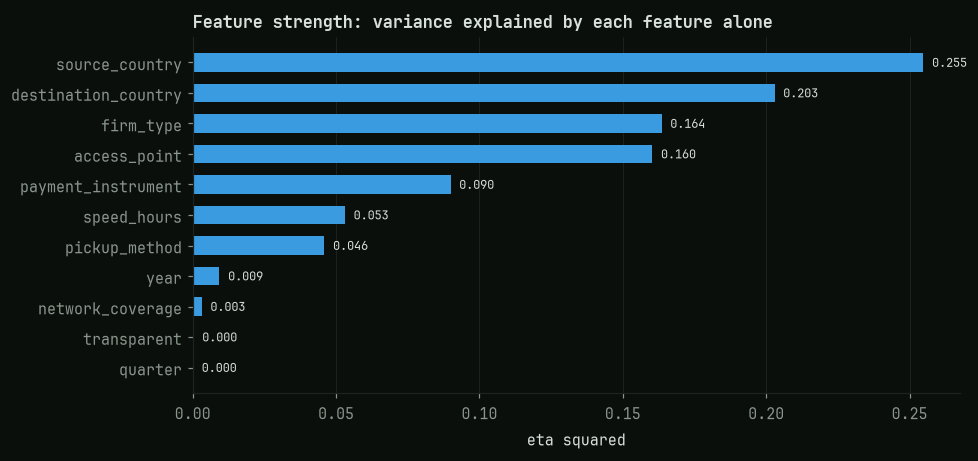

In [9]:
def correlation_ratio(groups, values):
    # eta^2: share of the target's variance explained by the feature's group means (works for categorical inputs).
    group_means = values.groupby(groups).transform("mean")
    return ((group_means - values.mean()) ** 2).sum() / ((values - values.mean()) ** 2).sum()


strength = pd.Series({f: correlation_ratio(data[f], y) for f in CANDIDATES}).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(strength.index, strength.values, color=BLUE, height=0.6)
for i, v in enumerate(strength.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8, color=INK)
ax.set(title="Feature strength: variance explained by each feature alone",
       xlabel="eta squared")
ax.grid(axis="y", visible=False)
plt.show()

**4.3 Feature strength.** **What it shows:** who sends and who receives matter most. Sending country alone explains **25.5%** of the variance and destination country **20.3%** (corridor competition, FX regimes, regulation), followed by provider type (16.4%) and access point (16.0%). These four are the features that matter most for the target.
**Decision:** `quarter` explains 0.000, so it is **dropped** (prices have no seasonality), leaving **10 inputs**. `transparent` also scores about 0 on its own but is **kept**: when a provider hides its exchange rate, the data records the FX margin as 0, so the target *understates* those quotes. The model needs this flag to read them correctly.

In [10]:
NUMERIC = ["speed_hours", "year"]  # 'quarter' dropped: eta squared = 0.000, so prices show no seasonality
FEATURES = CATEGORICAL + NUMERIC
print(f"final model inputs ({len(FEATURES)}): {FEATURES}")

final model inputs (10): ['source_country', 'destination_country', 'firm_type', 'payment_instrument', 'access_point', 'pickup_method', 'network_coverage', 'transparent', 'speed_hours', 'year']


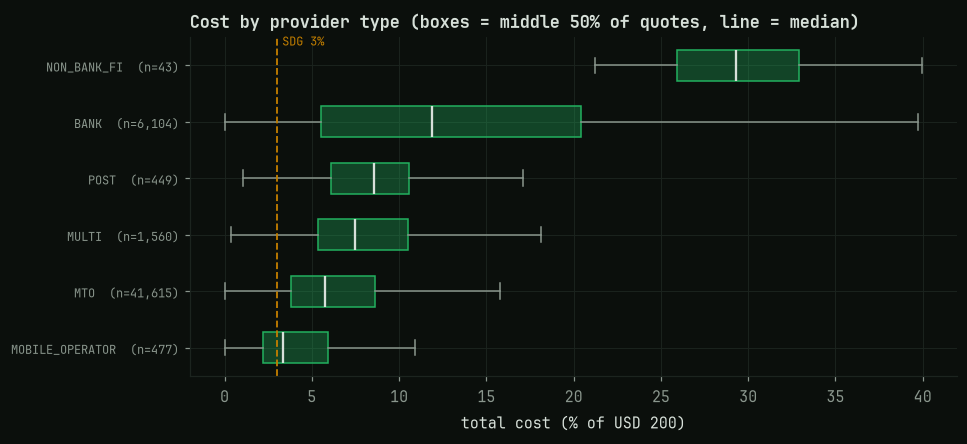

In [11]:
order = data.groupby("firm_type")[TARGET].median().sort_values().index
groups = [data.loc[data["firm_type"] == f, TARGET] for f in order]
fig, ax = plt.subplots(figsize=(9, 4))
box = ax.boxplot(groups, orientation="horizontal", showfliers=False, patch_artist=True, widths=0.55,
                 medianprops={"color": INK, "linewidth": 1.5}, whiskerprops={"color": MUTED},
                 capprops={"color": MUTED}, boxprops={"edgecolor": GREEN})
for patch in box["boxes"]:
    patch.set_facecolor(GREEN + "55")
ax.set_yticks(range(1, len(order) + 1), [f"{f}  (n={len(g):,})" for f, g in zip(order, groups)], fontsize=8)
ax.axvline(SDG_TARGET, color=AMBER, linestyle="--", linewidth=1.2)
ax.text(SDG_TARGET + 0.3, len(order) + 0.35, "SDG 3%", color=AMBER, fontsize=8)
ax.set(title="Cost by provider type (boxes = middle 50% of quotes, line = median)",
       xlabel="total cost (% of USD 200)")
plt.show()

**4.4 Cost by provider type.** **What it shows:** mobile operators are the only provider type whose median (about 3.3%) sits at the SDG target. Money-transfer operators dominate the market (41,615 quotes, median about 5.7%). Banks are both expensive (median about 12%) and extremely variable (the middle half of quotes spans about 5.5% to 20%).
**Decision:** provider type is a required input, and the huge spread *inside* BANK shows that one coefficient per type cannot explain cost. That is another reason to compare against tree models. It is also the mission insight: digital/mobile rails are already the cheapest, and that is the gap new rails must widen.

## 5. Encode, split and standardise

* **Encode:** `OneHotEncoder` turns each categorical column into 0/1 columns, and `handle_unknown="ignore"` means an unseen level becomes all-zeros instead of crashing. The 2 numeric columns (`speed_hours`, `year`) pass through unchanged.
* **Split:** 80% train / 20% test, with a fixed seed so every model is scored on exactly the same test rows.
* **Standardise:** `StandardScaler` puts every column at mean 0 and std 1, which SGD needs to converge. It is **fitted on the training set only**. The test set is transformed with the training means and standard deviations, so no test information leaks into training.

Both steps live in one scikit-learn `Pipeline`. Every model trained later reuses it, so the saved model carries its own preprocessing.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X, y = data[FEATURES], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

preprocess = Pipeline([
    ("encode", ColumnTransformer(
        [("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
        remainder="passthrough")),
    ("scale", StandardScaler()),
])
X_train_ready = preprocess.fit_transform(X_train)   # learns categories, means and stds from TRAIN only
X_test_ready = preprocess.transform(X_test)         # reuses them, so nothing is learned from test

print(f"train {X_train_ready.shape} | test {X_test_ready.shape}")
print(f"train columns: mean {X_train_ready.mean():+.3f}, std {X_train_ready.std():.3f}  (0 and 1 by construction)")
print(f"test  columns: mean {X_test_ready.mean():+.3f}, std {X_test_ready.std():.3f}  (close, not exact: scaler never saw test)")

train (40198, 95) | test (10050, 95)
train columns: mean +0.000, std 1.000  (0 and 1 by construction)
test  columns: mean -0.001, std 0.993  (close, not exact: scaler never saw test)


## 6. Train four regression models

Every model is the **same preprocessing pipeline + a different estimator**, scored with **mean squared error (MSE)** on the **same test rows**.

| Model | scikit-learn class | Why it is here |
|---|---|---|
| Linear regression by gradient descent | `SGDRegressor` | The main model: optimised epoch by epoch, with a recorded loss curve |
| Linear regression, closed form | `LinearRegression` | The exact least-squares solution, to check SGD against |
| Decision tree | `DecisionTreeRegressor` | Learns if-then interactions (e.g. *bank AND Nigeria*) |
| Random forest | `RandomForestRegressor` | An ensemble of trees that keeps the interactions but averages away a single tree's variance |

**Tuning without touching the test set:** hyperparameters are chosen on a *validation* split carved out of the training data (20% of train). The test set is used only once, for the final comparison. Choosing settings by test score would quietly leak test information into the model.

In [13]:
import copy
import time

import joblib
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor

X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=SEED)
tuning_prep = clone(preprocess).fit(X_fit)            # fitted on the fit-part only, like the real scaler
X_fit_ready, X_val_ready = tuning_prep.transform(X_fit), tuning_prep.transform(X_val)


def with_preprocessing(estimator):
    return Pipeline([("prep", clone(preprocess)), ("model", estimator)])


def validation_mse(estimator):
    return mean_squared_error(y_val, with_preprocessing(estimator).fit(X_fit, y_fit).predict(X_val))


print(f"fit {X_fit_ready.shape} | validation {X_val_ready.shape} | test {X_test_ready.shape} (untouched)")

fit (32158, 95) | validation (8040, 95) | test (10050, 95) (untouched)


### 6.1 Linear regression by gradient descent (`SGDRegressor`)

scikit-learn does not record a loss history, so the model is trained **one epoch at a time with `partial_fit`**: the rows are shuffled, one pass is made over them, and the MSE is recorded after each epoch. Three hyperparameters are tuned:

* **learning rate** `eta0` (constant step size): 0.00001, 0.0001, 0.001, 0.01
* **regularisation strength** `alpha` (L2 penalty on the weights): 0.0001, 0.01, 0.1, 1.0
* **number of epochs**: up to 50, keeping the epoch with the lowest validation MSE

In [14]:
LEARNING_RATES = [0.00001, 0.0001, 0.001, 0.01]
ALPHAS = [0.0001, 0.01, 0.1, 1.0]
MAX_EPOCHS = 50
DIVERGED = 1e6  # an MSE this large means the weights exploded


def train_sgd(eta0, alpha, X_a, y_a, X_b, y_b, epochs=MAX_EPOCHS, keep_epoch=None):
    # One partial_fit call = one shuffled epoch on (X_a, y_a); MSE on both sets is recorded after every epoch.
    # Returns (model snapshot, history): the snapshot at `keep_epoch`, or else at the epoch with the lowest MSE on set b.
    rng = np.random.default_rng(SEED)
    sgd = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, penalty="l2", random_state=SEED)
    history, best_model, best_mse = [], None, np.inf
    for _ in range(epochs):
        order = rng.permutation(len(X_a))
        sgd.partial_fit(X_a[order], y_a[order])
        pred_a, pred_b = sgd.predict(X_a), sgd.predict(X_b)
        if not (np.isfinite(pred_b).all() and mean_squared_error(y_b, pred_b) < DIVERGED):
            history.append((np.inf, np.inf))
            break
        history.append((mean_squared_error(y_a, pred_a), mean_squared_error(y_b, pred_b)))
        if (keep_epoch is None and history[-1][1] < best_mse) or len(history) == keep_epoch:
            best_mse, best_model = history[-1][1], copy.deepcopy(sgd)
    return best_model, np.array(history)


start = time.time()
sgd_runs = {(eta0, alpha): train_sgd(eta0, alpha, X_fit_ready, y_fit.to_numpy(), X_val_ready, y_val.to_numpy())[1]
            for eta0 in LEARNING_RATES for alpha in ALPHAS}
grid = pd.DataFrame([{"learning rate (eta0)": eta0, "alpha": alpha,
                      "best validation MSE": h[:, 1].min(), "best epoch": int(h[:, 1].argmin()) + 1,
                      "diverged": not np.isfinite(h[-1, 1])}
                     for (eta0, alpha), h in sgd_runs.items()])
best_sgd = grid.loc[grid["best validation MSE"].idxmin()]
BEST_ETA0, BEST_ALPHA, BEST_EPOCHS = best_sgd["learning rate (eta0)"], best_sgd["alpha"], int(best_sgd["best epoch"])
print(f"{len(sgd_runs)} configurations in {time.time() - start:.0f}s -> best: eta0={BEST_ETA0}, "
      f"alpha={BEST_ALPHA}, epochs={BEST_EPOCHS}, validation MSE={best_sgd['best validation MSE']:.3f}")
grid.pivot(index="learning rate (eta0)", columns="alpha", values="best validation MSE").round(3)

16 configurations in 16s -> best: eta0=0.0001, alpha=0.01, epochs=41, validation MSE=17.830


alpha,0.0001,0.0100,0.1000,1.0000
learning rate (eta0),,,,
0.00001,17.860,17.856,17.908,19.831
0.00010,17.835,17.830,17.890,19.703
0.00100,18.522,18.511,18.474,19.830
0.01000,inf,inf,inf,23.978


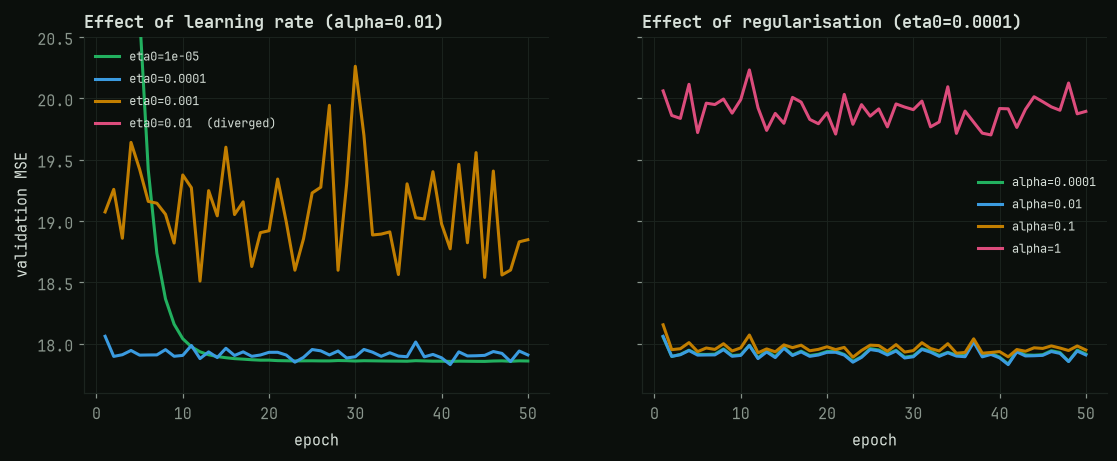

In [15]:
SERIES = [GREEN, BLUE, AMBER, ROSE]  # fixed categorical order
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
panels = [("learning rate", [(f"eta0={e:g}", sgd_runs[(e, BEST_ALPHA)]) for e in LEARNING_RATES], f"alpha={BEST_ALPHA:g}"),
          ("regularisation", [(f"alpha={a:g}", sgd_runs[(BEST_ETA0, a)]) for a in ALPHAS], f"eta0={BEST_ETA0:g}")]
for ax, (name, runs, fixed) in zip(axes, panels):
    for color, (label, history) in zip(SERIES, runs):
        finite = history[np.isfinite(history[:, 1]), 1]
        if len(finite) < len(history) or len(finite) == 0:
            label += "  (diverged)"
        ax.plot(range(1, len(finite) + 1), finite, color=color, linewidth=2, label=label)
    ax.set(title=f"Effect of {name} ({fixed})", xlabel="epoch", ylim=(17.6, 20.5))
    ax.legend(frameon=False, fontsize=8, labelcolor=INK)
axes[0].set_ylabel("validation MSE")
plt.show()

**What tuning showed.**
* **Learning rate** has by far the biggest effect. `0.00001` is too timid: it still improves at epoch 50. `0.0001` converges within a few epochs to the lowest loss. `0.001` keeps overshooting, so the loss bounces around a higher level. `0.01` **diverges**: the weights explode. That happens because rare one-hot columns become large numbers (around 30) after standardising, and a big step on them throws the weights off.
* **Regularisation** matters much less. Small `alpha` values give almost the same loss, while `alpha = 1.0` over-shrinks the weights and the loss rises, so the model underfits.
* **Epochs:** the best validation loss arrives early. Training longer at a constant step only adds noise, so the epoch count is chosen from the validation curve.

**Loss curve (required).** The best settings are retrained on the full training set for `MAX_EPOCHS`, recording **train and test MSE after every epoch** on one chart. The deployed SGD weights are those of the epoch chosen on validation.

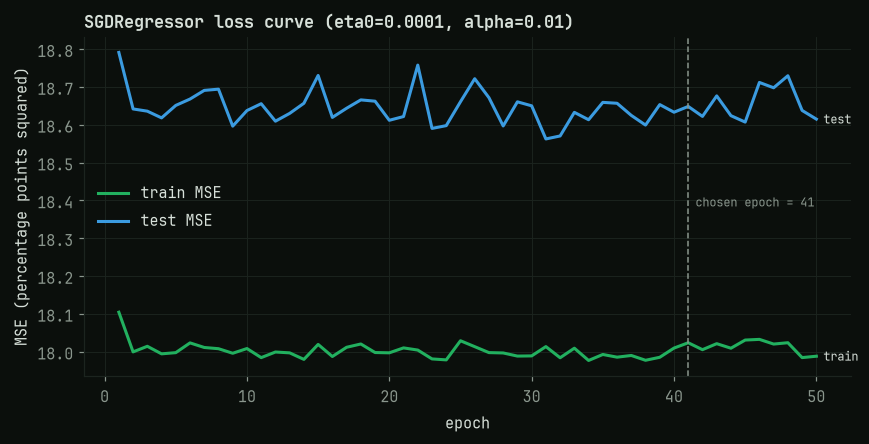

epoch 1: train 18.10 / test 18.79 | epoch 50: train 17.99 / test 18.62


In [16]:
# Test MSE is only *recorded* here; the kept weights are from BEST_EPOCHS, which was chosen on validation.
sgd_final, sgd_history = train_sgd(BEST_ETA0, BEST_ALPHA, X_train_ready, y_train.to_numpy(),
                                   X_test_ready, y_test.to_numpy(), keep_epoch=BEST_EPOCHS)

epochs = np.arange(1, len(sgd_history) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs, sgd_history[:, 0], color=GREEN, linewidth=2, label="train MSE")
ax.plot(epochs, sgd_history[:, 1], color=BLUE, linewidth=2, label="test MSE")
ax.axvline(BEST_EPOCHS, color=MUTED, linestyle="--", linewidth=1)
ax.text(BEST_EPOCHS + 0.5, sum(ax.get_ylim()) / 2, f"chosen epoch = {BEST_EPOCHS}", color=MUTED, fontsize=8)
ax.text(epochs[-1], sgd_history[-1, 0], " train", color=INK, fontsize=8, va="center")
ax.text(epochs[-1], sgd_history[-1, 1], " test", color=INK, fontsize=8, va="center")
ax.set(title=f"SGDRegressor loss curve (eta0={BEST_ETA0:g}, alpha={BEST_ALPHA:g})",
       xlabel="epoch", ylabel="MSE (percentage points squared)")
ax.legend(frameon=False, labelcolor=INK)
plt.show()
print(f"epoch 1: train {sgd_history[0, 0]:.2f} / test {sgd_history[0, 1]:.2f} | "
      f"epoch {len(epochs)}: train {sgd_history[-1, 0]:.2f} / test {sgd_history[-1, 1]:.2f}")

**Reading the loss curve.** Train MSE settles near **18.0** and test MSE near **18.6** within the first few epochs, then only jitters. The gap between them is small (about 0.6), so the linear model is **not overfitting. It is underfitting** (high bias). No learning rate or epoch count fixes that. A straight-line model can only add a fixed amount per category, so it cannot express interactions such as *"bank AND sending from South Africa"*. That limit is why the tree models come next.

### 6.2 Closed-form linear regression, decision tree and random forest

* **`LinearRegression`** solves least squares exactly, so there is nothing to tune.
* **Decision tree:** depth and minimum leaf size are tuned on validation. Without limits, a tree memorises the training set.
* **Random forest:** `n_estimators` is **fixed at 60** as a deployment constraint. The API runs on Render's free tier (0.1 CPU, 512 MB RAM) and retrains on demand. A benchmark showed 100 trees improve test MSE by only about 0.02 while making the file 70% larger and retraining slower. Leaf size and the share of features tried at each split are tuned.

In [17]:
tree_grid = pd.DataFrame([{"max_depth": d, "min_samples_leaf": leaf,
                           "validation MSE": validation_mse(DecisionTreeRegressor(max_depth=d, min_samples_leaf=leaf,
                                                                                   random_state=SEED))}
                          for d in [10, 20, 30, None] for leaf in [1, 2, 5, 10]])
best_tree = tree_grid.loc[tree_grid["validation MSE"].idxmin()]
TREE_DEPTH = None if pd.isna(best_tree["max_depth"]) else int(best_tree["max_depth"])
TREE_LEAF = int(best_tree["min_samples_leaf"])

N_TREES = 60
forest_grid = pd.DataFrame([{"min_samples_leaf": leaf, "max_features": mf,
                             "validation MSE": validation_mse(RandomForestRegressor(
                                 n_estimators=N_TREES, min_samples_leaf=leaf, max_features=mf,
                                 n_jobs=-1, random_state=SEED))}
                            for leaf in [1, 2, 4] for mf in ["sqrt", 0.3, 0.5]])
best_forest = forest_grid.loc[forest_grid["validation MSE"].idxmin()]
FOREST_LEAF, FOREST_FEATURES = int(best_forest["min_samples_leaf"]), best_forest["max_features"]

print(f"decision tree -> max_depth={TREE_DEPTH}, min_samples_leaf={TREE_LEAF} "
      f"(validation MSE {best_tree['validation MSE']:.3f})")
print(f"random forest -> n_estimators={N_TREES}, min_samples_leaf={FOREST_LEAF}, max_features={FOREST_FEATURES} "
      f"(validation MSE {best_forest['validation MSE']:.3f})")
forest_grid.pivot(index="min_samples_leaf", columns="max_features", values="validation MSE").round(3)

decision tree -> max_depth=None, min_samples_leaf=5 (validation MSE 8.826)
random forest -> n_estimators=60, min_samples_leaf=2, max_features=0.3 (validation MSE 7.628)


max_features,0.3,0.5,sqrt
min_samples_leaf,,,
1,8.018,7.994,8.047
2,7.628,7.717,7.963
4,8.023,7.864,8.970


## 7. Compare all four on the same test set

In [18]:
models = {
    "SGDRegressor (gradient descent)": Pipeline([("prep", preprocess), ("model", sgd_final)]),  # prep fitted on train
    "LinearRegression (closed form)": with_preprocessing(LinearRegression()).fit(X_train, y_train),
    "DecisionTreeRegressor": with_preprocessing(DecisionTreeRegressor(
        max_depth=TREE_DEPTH, min_samples_leaf=TREE_LEAF, random_state=SEED)).fit(X_train, y_train),
    "RandomForestRegressor": with_preprocessing(RandomForestRegressor(
        n_estimators=N_TREES, min_samples_leaf=FOREST_LEAF, max_features=FOREST_FEATURES,
        n_jobs=-1, random_state=SEED)).fit(X_train, y_train),
}

rows = []
for name, model in models.items():
    test_pred = model.predict(X_test)
    rows.append({"model": name,
                 "train MSE": mean_squared_error(y_train, model.predict(X_train)),
                 "test MSE": mean_squared_error(y_test, test_pred),
                 "test RMSE (pts)": mean_squared_error(y_test, test_pred) ** 0.5,
                 "test R2": r2_score(y_test, test_pred)})
comparison = pd.DataFrame(rows).sort_values("test MSE").reset_index(drop=True)
BEST_NAME = comparison.loc[0, "model"]
best_model = models[BEST_NAME]
print(f"BEST MODEL = {BEST_NAME}: lowest test MSE {comparison.loc[0, 'test MSE']:.3f} "
      f"(typical error +/- {comparison.loc[0, 'test RMSE (pts)']:.2f} percentage points)")
comparison.round(3)

BEST MODEL = RandomForestRegressor: lowest test MSE 7.411 (typical error +/- 2.72 percentage points)


,model,train MSE,test MSE,test RMSE (pts),test R2
0,RandomForestRegressor,5.181,7.411,2.722,0.782
1,DecisionTreeRegressor,5.932,8.096,2.845,0.762
2,LinearRegression (closed form),17.934,18.578,4.310,0.454
3,SGDRegressor (gradient descent),18.024,18.649,4.318,0.452


**Best model: `RandomForestRegressor`**, chosen by the criterion fixed at the start: the **lowest test MSE (7.41)**. That is a typical error of **+/- 2.72 percentage points**, on a target whose own spread is +/- 5.84 points (test R2 = 0.78). This pipeline is the one saved to `API/best_model.pkl` below.

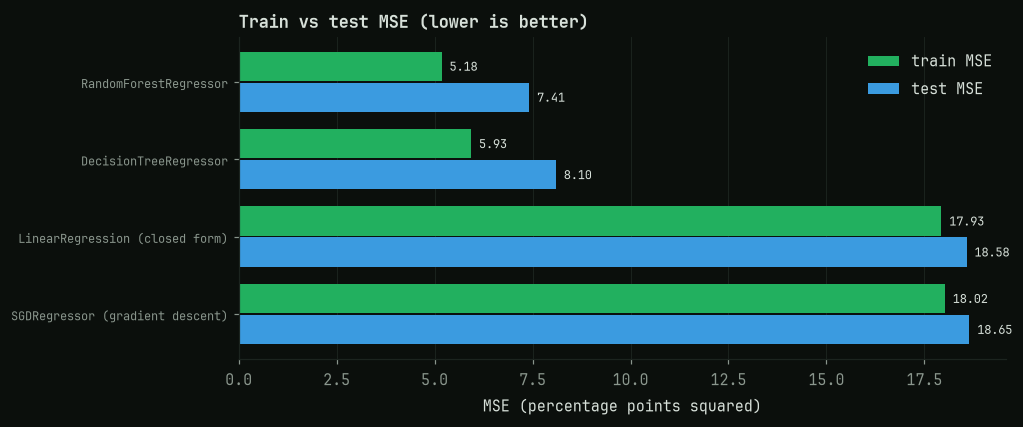

In [19]:
order = comparison.sort_values("test MSE", ascending=False)
positions = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(positions + 0.2, order["train MSE"], height=0.38, color=GREEN, label="train MSE")
ax.barh(positions - 0.2, order["test MSE"], height=0.38, color=BLUE, label="test MSE")
for p, (tr, te) in enumerate(zip(order["train MSE"], order["test MSE"])):
    ax.text(tr + 0.2, p + 0.2, f"{tr:.2f}", va="center", fontsize=8, color=INK)
    ax.text(te + 0.2, p - 0.2, f"{te:.2f}", va="center", fontsize=8, color=INK)
ax.set_yticks(positions, order["model"], fontsize=8)
ax.set(title="Train vs test MSE (lower is better)", xlabel="MSE (percentage points squared)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, labelcolor=INK, loc="upper right")
plt.show()

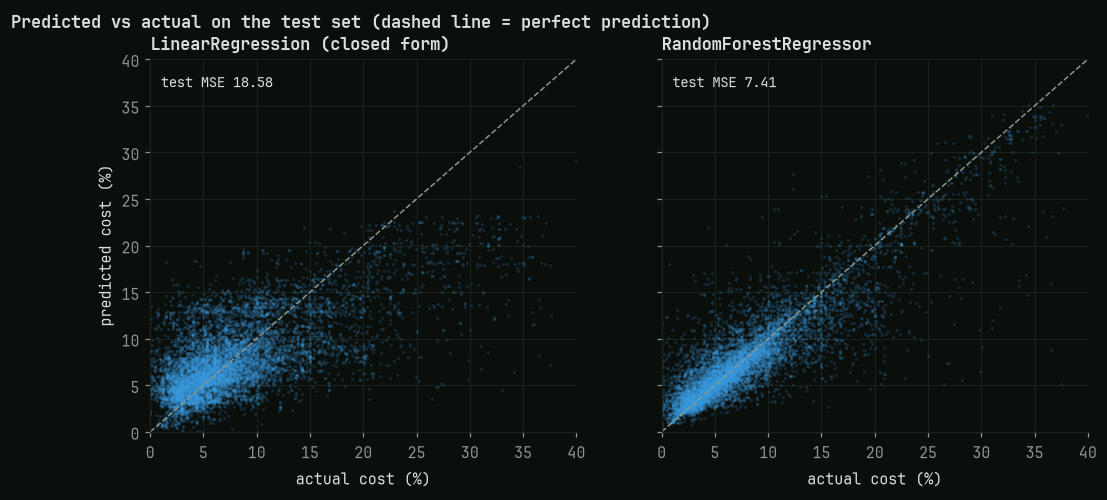

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, name in zip(axes, ["LinearRegression (closed form)", BEST_NAME]):
    pred = models[name].predict(X_test)
    ax.scatter(y_test, pred, s=4, alpha=0.18, color=BLUE, linewidths=0)
    ax.plot([0, 40], [0, 40], color=MUTED, linestyle="--", linewidth=1)
    ax.text(1, 37, f"test MSE {mean_squared_error(y_test, pred):.2f}", color=INK, fontsize=9)
    ax.set(title=name, xlabel="actual cost (%)", xlim=(0, 40), ylim=(0, 40))
axes[0].set_ylabel("predicted cost (%)")
fig.suptitle("Predicted vs actual on the test set (dashed line = perfect prediction)", x=0.01, ha="left",
             fontsize=11, fontweight="bold", color=INK)
plt.show()

### 7.1 How the dataset shaped each model's performance

* **Linear models (SGD 18.65, closed form 18.58).** They are almost identical, as they should be: SGD is just an iterative route to the same least-squares solution, and its small gap comes from the L2 penalty and stopping at epoch 41. Both **underfit** (train about equal to test, about 18). Remittance prices are set per corridor and per channel, as step-changes and *interactions*, and a sum of one-hot effects cannot represent that. The predicted-vs-actual plot shows it: the linear model flattens out and never predicts the expensive 20-40% quotes.
* **Decision tree (8.10).** Splitting on combinations captures those interactions and **more than halves the error**. A single tree still overfits rare corridors (train 5.93 vs test 8.10): with 38 destinations and 29 sending countries, many combinations have only a handful of quotes.
* **Random forest (7.41, best).** Each of the 60 trees sees a bootstrap sample and a random 30% of the columns, so averaging keeps the interactions and cancels out single-tree quirks. It tracks the diagonal even for expensive quotes. Most of the remaining error is the *provider* effect, excluded on purpose (two transfer operators on the same corridor can differ by several points), plus noisy recordings.
* **Why it is the right choice for this problem.** The use case is benchmarking the price of a *service profile* in any corridor, so accuracy across corridors matters more than readable coefficients. The saved forest is 15.5 MB and refits in seconds, which suits a free Render instance that retrains on demand.

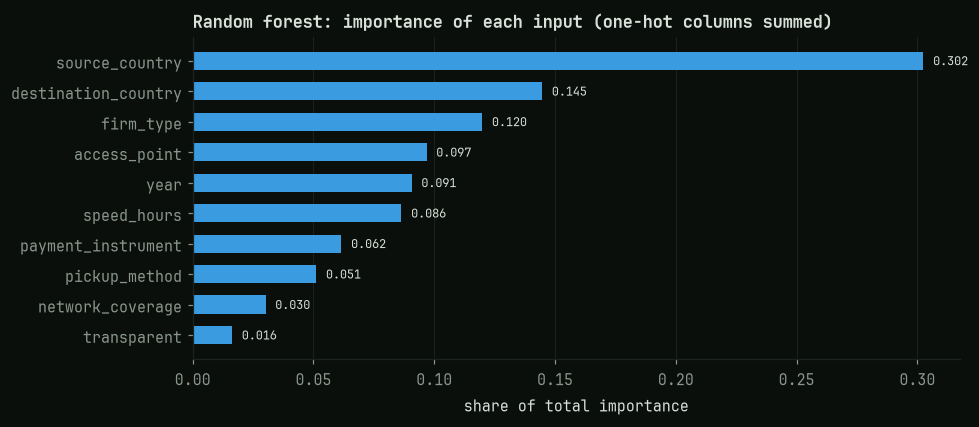

In [21]:
forest_pipeline = models["RandomForestRegressor"]
encoded_names = forest_pipeline.named_steps["prep"].get_feature_names_out()
source_feature = [next(f for f in FEATURES if name.split("__", 1)[1].startswith(f)) for name in encoded_names]
importance = pd.Series(forest_pipeline.named_steps["model"].feature_importances_).groupby(source_feature).sum().sort_values()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
for i, v in enumerate(importance.values):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color=INK)
ax.set(title="Random forest: importance of each input (one-hot columns summed)", xlabel="share of total importance")
ax.grid(axis="y", visible=False)
plt.show()

**Which features matter most (model view).** The forest agrees with the EDA. **Sending country (0.30)** and **destination country (0.15)** dominate, followed by provider type (0.12) and access point (0.10). `year` (0.09) ranks higher here than in the single-feature view because the trees use it to separate old and new pricing *within* a corridor, i.e. the slow downward trend. `transparent` contributes least (0.016) but is not zero, which confirms it helps on the minority of quotes that hide their exchange rate.

## 8. Required scatter plots: the most correlated feature, before and after a fitted line

The feature most correlated with the target is found on the **training set**, among all encoded inputs. A **one-feature** `LinearRegression` is then fitted for the second plot only. When that feature is a 0/1 indicator, the points are spread with a little horizontal jitter so the two groups are visible. The jitter is only for display.

most correlated feature: source_country_ZAF (r = +0.405)


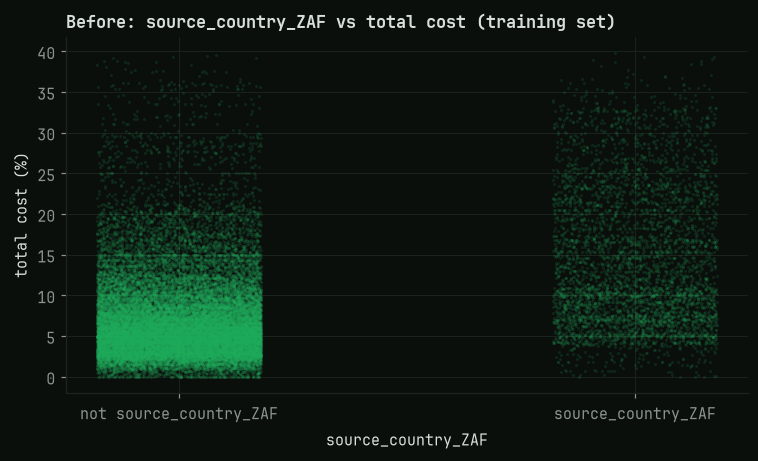

In [22]:
encoder = models["LinearRegression (closed form)"].named_steps["prep"].named_steps["encode"]
train_encoded = pd.DataFrame(encoder.transform(X_train), columns=encoder.get_feature_names_out(), index=X_train.index)
correlations = train_encoded.corrwith(y_train)
TOP_FEATURE = correlations.abs().idxmax()
x_top = train_encoded[TOP_FEATURE].to_numpy()
is_binary = set(np.unique(x_top)) <= {0.0, 1.0}
x_plot = x_top + (np.random.default_rng(SEED).uniform(-0.18, 0.18, len(x_top)) if is_binary else 0)
pretty = TOP_FEATURE.split("__", 1)[1]
print(f"most correlated feature: {pretty} (r = {correlations[TOP_FEATURE]:+.3f})")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(x_plot, y_train, s=4, alpha=0.15, color=GREEN, linewidths=0)
if is_binary:
    ax.set_xticks([0, 1], [f"not {pretty}", pretty])
ax.set(title=f"Before: {pretty} vs total cost (training set)", ylabel="total cost (%)", xlabel=pretty)
plt.show()

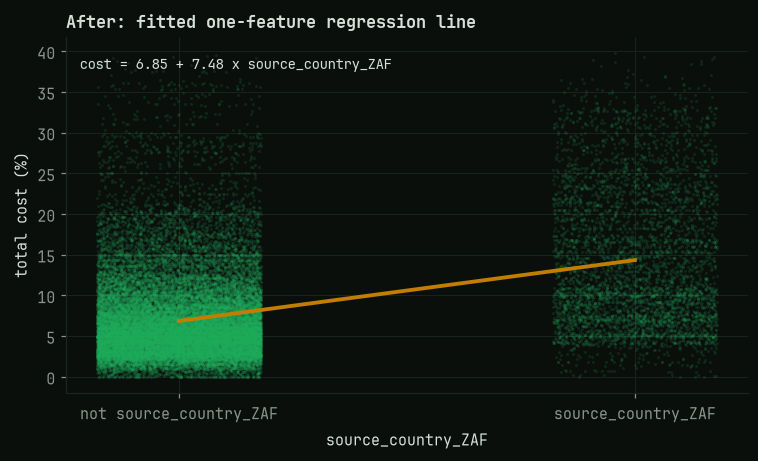

one-feature model: intercept 6.85, slope +7.48 -> on its own, this feature moves the predicted cost by +7.48 percentage points


In [23]:
one_feature = LinearRegression().fit(x_top.reshape(-1, 1), y_train)
grid_x = np.linspace(x_top.min(), x_top.max(), 50)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(x_plot, y_train, s=4, alpha=0.15, color=GREEN, linewidths=0)
ax.plot(grid_x, one_feature.predict(grid_x.reshape(-1, 1)), color=AMBER, linewidth=2.5)
ax.text(0.02, 0.95, f"cost = {one_feature.intercept_:.2f} + {one_feature.coef_[0]:.2f} x {pretty}",
        transform=ax.transAxes, color=INK, fontsize=9, va="top")
if is_binary:
    ax.set_xticks([0, 1], [f"not {pretty}", pretty])
ax.set(title=f"After: fitted one-feature regression line", ylabel="total cost (%)", xlabel=pretty)
plt.show()
print(f"one-feature model: intercept {one_feature.intercept_:.2f}, slope {one_feature.coef_[0]:+.2f} -> "
      f"on its own, this feature moves the predicted cost by {one_feature.coef_[0]:+.2f} percentage points")

**Reading the line.** The most correlated encoded feature is **sending from South Africa** (r = +0.41). The fitted line says quotes sent *from* South Africa cost on average **6.85 + 7.48 = 14.3%**, against **6.85%** from everywhere else, more than double. These are intra-African corridors (South Africa to Zimbabwe, Zambia, Mozambique, Botswana, Malawi at a 15.9% median, Nigeria...), the most expensive routes in the data and exactly where cheaper digital rails would help most. The huge vertical spread that remains around the line shows why one feature is not enough and the full model needs all ten inputs.

## 9. Save the best model with its preprocessing

The winning **Pipeline** (one-hot encoder + scaler + model) is saved with `joblib` straight into the API folder, so the API cannot drift out of sync with the notebook. The cleaned train/test data and the held-out **Q3 2025** quarter are saved next to it: the API's `/retrain` endpoint refits on *original training data + new rows* and re-scores on the same test set.

In [24]:
API_DIR = Path("../API")
MODEL_PATH = API_DIR / "best_model.pkl"
(API_DIR / "data").mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, MODEL_PATH, compress=3)
X_train.assign(**{TARGET: y_train}).to_csv(API_DIR / "data" / "train.csv.gz", index=False)
X_test.assign(**{TARGET: y_test}).to_csv(API_DIR / "data" / "test.csv.gz", index=False)
new_quarter[FEATURES + [TARGET]].to_csv(API_DIR / "data" / "new_quarter_2025Q3.csv", index=False)
print(f"saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB) | {BEST_NAME}")
print("saved train / test data and the Q3 2025 file for /retrain:", sorted(p.name for p in (API_DIR / "data").iterdir()))

saved ..\API\best_model.pkl (15.5 MB) | RandomForestRegressor
saved train / test data and the Q3 2025 file for /retrain: ['new_quarter_2025Q3.csv', 'test.csv.gz', 'train.csv.gz']


## 10. Predict one row with the saved model

`predict_total_cost` loads the saved file and predicts the cost for one quote. The API's `/predict` route reuses exactly this function.

In [25]:
def predict_total_cost(features: dict, model_path: Path = MODEL_PATH) -> float:
    # Load the saved pipeline (preprocessing + model) and return the predicted all-in cost in %.
    model = joblib.load(model_path)
    return round(float(model.predict(pd.DataFrame([features], columns=FEATURES))[0]), 2)


one_row = X_test.iloc[0].to_dict()
predicted = predict_total_cost(one_row)
print("input (first row of the test set):")
for key, value in one_row.items():
    print(f"  {key:20s} {value}")
print(f"\npredicted cost {predicted:.2f}% | actual {y_test.iloc[0]:.2f}% | error {predicted - y_test.iloc[0]:+.2f} pts")

input (first row of the test set):
  source_country       ZAF
  destination_country  AGO
  firm_type            MTO
  payment_instrument   CASH
  access_point         AGENT
  pickup_method        CASH
  network_coverage     HIGH
  transparent          yes
  speed_hours          1
  year                 2016

predicted cost 14.35% | actual 13.24% | error +1.11 pts
